# 1. Check for the outliers in the monthly rent box plots

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()

DERIVED_DIR = PROJECT_ROOT / "derived"
TRAIN_PATH = PROJECT_ROOT / "train.csv"
TEST_PATH = PROJECT_ROOT / "test.csv"

TRAIN_ENRICHED_PATH = DERIVED_DIR / "train_location_enriched.csv"
TEST_ENRICHED_PATH = DERIVED_DIR / "test_location_enriched.csv"

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/apple/Documents/modules/CS5228/cs-5228-2610-project


In [2]:
train = pd.read_csv(TRAIN_ENRICHED_PATH)
test = pd.read_csv(TEST_ENRICHED_PATH)

train.sort_values("MONTHLY_RENT", ascending=False).head(20)

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT,LOCATION_KEY,HDB_LATITUDE,HDB_LONGITUDE,HDB_YEAR_COMPLETED,HDB_SUBZONE,HDB_PLANNING_AREA,NEAREST_MRT_KM,NEAREST_SCHOOL_KM,NEAREST_MALL_KM
101586,2023-11,central,2,tanjong pagar plaza,5-room,adjoined flat,129.0,yes,1977,0.0,7600,central|2|tanjong pagar plaza,1.275237,103.842605,1976.0,chinatown,outram,0.370252,0.294911,0.399459
96685,2023-09,geylang,11,Pine Close,5-room,improved,113.0,yes,2000,0.0,7400,geylang|11|pine close,1.308113,103.882694,1998.0,aljunied,geylang,0.192910,0.484189,0.946446
100082,2023-11,queenstown,13,Holland Drive,5-room,adjoined flat,147.0,yes,1975,0.0,6800,queenstown|13|holland drive,1.309360,103.793205,1974.0,holland drive,queenstown,0.418968,1.119965,0.273955
82064,2023-05,choa chu kang,641,choa chu kang street 64,executive,premium maisonette,215.0,yes,1998,0.0,6600,choa chu kang|641|choa chu kang street 64,1.398305,103.749818,1996.0,yew tee,choa chu kang,0.272778,0.214806,0.292765
90975,2023-07,tampines,110,tampines street 11,executive,adjoined flat,152.0,yes,1984,0.0,6550,tampines|110|tampines street 11,1.346947,103.949307,1983.0,tampines east,tampines,0.579933,0.478486,0.627044
107322,2024-01,queenstown,13,holland drive,5-room,adjoined flat,147.0,yes,1975,0.0,6500,queenstown|13|holland drive,1.309360,103.793205,1974.0,holland drive,queenstown,0.418968,1.119965,0.273955
127064,2024-07,kallang/whampoa,93,whampoa drive,5-room,adjoined flat,151.0,yes,1974,0.0,6500,kallang whampoa|93|whampoa drive,1.322276,103.854800,1973.0,balestier,novena,0.825775,0.319620,1.195551
73524,2023-02,ang mo kio,549,ang mo kio avenue 10,5-room,adjoined flat,136.0,yes,1981,0.0,6500,ang mo kio|549|ang mo kio avenue 10,1.373165,103.857412,1980.0,cheng san,ang mo kio,0.746378,0.595999,1.078235
91751,2023-08,queenstown,170,stirling road,5-room,adjoined flat,139.0,yes,1970,0.0,6400,queenstown|170|stirling road,1.290909,103.803108,1970.0,mei chin,queenstown,0.515753,0.717661,0.369880
95642,2023-09,queenstown,2,holland avenue,5-room,adjoined flat,130.0,yes,1974,0.0,6300,queenstown|2|holland avenue,1.309345,103.795559,1974.0,holland drive,queenstown,0.295439,1.191294,0.306711


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

train["FLAT_TYPE"] = (
    train["FLAT_TYPE"].astype("string").str.lower()
    .str.replace(r"[\s-]+", "-", regex=True).str.strip()
)

eda = train.assign(
    rent_band=pd.cut(
        train["MONTHLY_RENT"],
        bins=[-float("inf"), 2000, 4500, float("inf")],
        labels=["Low", "Medium", "High"],
    )
)

counts = pd.crosstab(eda["FLAT_TYPE"], eda["rent_band"])
display(counts)

rent_band,Low,Medium,High
FLAT_TYPE,,,
1-room,40,2,0
2-room,1532,1566,0
3-room,17228,31749,47
4-room,8987,44550,542
5-room,4345,30417,761
executive,726,7268,240


In [11]:
counts = pd.crosstab(eda["FLAT_MODEL"], eda["rent_band"])
display(counts)

rent_band,Low,Medium,High
FLAT_MODEL,,,
2 room,70,154,0
3gen,0,12,0
adjoined flat,27,137,54
apartment,404,4217,103
dbss,41,968,81
improved,8896,34673,439
improved maisonette,0,1,0
maisonette,177,2057,112
model a,8791,33645,309


In [12]:
counts = pd.crosstab(eda["TOWN"], eda["rent_band"])
display(counts)

rent_band,Low,Medium,High
TOWN,,,
ang mo kio,2384,5882,17
bedok,2404,6473,30
bishan,353,2888,65
bukit batok,1552,4045,8
bukit merah,1172,6762,336
bukit panjang,1017,2698,2
bukit timah,58,358,22
central,208,1801,269
choa chu kang,1374,3920,6


In [13]:
counts = pd.crosstab(eda["RENT_APPROVAL_DATE"], eda["rent_band"])
display(counts)

rent_band,Low,Medium,High
RENT_APPROVAL_DATE,,,
2021-01,1722,1407,0
2021-02,1450,1230,0
2021-03,1953,1752,0
2021-04,1529,1472,0
2021-05,1736,1764,0
2021-06,1553,1682,0
2021-07,1482,1689,0
2021-08,1394,1665,0
2021-09,1380,1606,0


## 2. What the rent-band counts suggest

- High rents (>4,500) are 1,590/150,000 rows (1.06%). Compare within-group percentages as well as counts.
- Type S1: 155/299 (51.8%) high; Type S2: 101/160 (63.1%); adjoined flats: 54/218 (24.8%). These are much stronger concentrations than improved flats: 439/44,008 (1.0%), despite improved having more high-rent rows.
- Central: 269/2,278 (11.8%) high; Queenstown: 287/6,115 (4.7%); Bukit Merah: 336/8,270 (4.1%). Together these towns contain 56.1% of all high-rent rows.
- No high-rent rows occur before July 2022. Low-rent prevalence falls from 55.0% in January 2021 to 4.8% in March 2025. Time must be included.
- These are overlapping associations, not independent causal effects. Flat model, location and date can explain the same rows. Rare categories need cautious interpretation; zero historical high rents is not a permanent price ceiling.

Keep legitimate extremes. Do not use rent_band or rent/area as input features: both use the target. The following baseline uses all three rent bands together.


## 3. CatBoost with location-enriched features

Run these cells independently of the earlier EDA. Requires catboost, pandas, scikit-learn and matplotlib. The categorical and numeric feature lists are editable; your current selection excludes STREET and LOCATION_KEY.

CatBoost consumes cleaned categorical strings directly, including previously unseen labels. Missing categories use "<missing>"; numeric NaNs are handled by the model. No scaling or manual category encoding is needed.

The latest 12 months are validation, matching the earlier comparison. Change VALIDATION_MONTHS to 16 to approximate the test horizon. Early stopping uses validation, so this is a model-selection score. Date features do not guarantee trend extrapolation. Amenity distances use the supplied snapshot, whose historical availability has not been verified.

[CatBoost training documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit).


In [6]:
# Uncomment if CBoost is not installed in this notebook's kernel:
# %pip install catboost

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

CB_ROOT = Path.cwd()
cb_train = pd.read_csv(CB_ROOT / "derived/train_location_enriched.csv",
                        dtype={"BLOCK": "string"})
cb_test = pd.read_csv(CB_ROOT / "derived/test_location_enriched.csv",
                       dtype={"BLOCK": "string"})

CB_TARGET = "MONTHLY_RENT"

CB_CATEGORICAL = [
    "TOWN", "FLAT_TYPE", "FLAT_MODEL",
    "HDB_SUBZONE", "HDB_PLANNING_AREA",
]

CB_NUMERIC = [
    "FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE",
    "HDB_LATITUDE", "HDB_LONGITUDE", "HDB_YEAR_COMPLETED",
    "NEAREST_MRT_KM", "NEAREST_SCHOOL_KM", "NEAREST_MALL_KM",
]
VALIDATION_MONTHS = 12
CB_PARAMS = dict(
    loss_function="RMSE", eval_metric="RMSE",
    depth=6, learning_rate=0.05,
    l2_leaf_reg=5.0, random_seed=42, thread_count=4,
    allow_writing_files=False,
)
MAX_TREES = 2000
EARLY_STOPPING_ROUNDS = 100


In [7]:
def make_cb_features(data):
    """Explicit feature allowlist excludes target and EDA-derived columns."""
    X = data[CB_CATEGORICAL + CB_NUMERIC].copy()
    
    for col in CB_CATEGORICAL:
        values = X[col].astype("string").str.strip().str.lower()
        values = values.str.replace(r"\s+", " ", regex=True)
        if col == "FLAT_TYPE":
            values = values.str.replace(r"^(\d+)\s*[- ]\s*room$", r"\1-room", regex=True)
        X[col] = values.fillna("<missing>").replace("", "<missing>").astype(object)
    
    for col in CB_NUMERIC:
        X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)
    
    X["HDB_YEAR_COMPLETED"] = X["HDB_YEAR_COMPLETED"].replace(-1, np.nan)
    dates = pd.to_datetime(data["RENT_APPROVAL_DATE"], format="%Y-%m", errors="raise")
    if dates.isna().any():
        raise ValueError("Approval dates must not be missing.")
    
    X["APPROVAL_YEAR"] = dates.dt.year
    X["APPROVAL_MONTH"] = dates.dt.month
    X["MONTH_INDEX"] = (dates.dt.year - 2021) * 12 + dates.dt.month - 1
    X["LEASE_AGE"] = dates.dt.year - X["LEASE_COMMENCE_DATE"]
    X["BUILDING_AGE"] = dates.dt.year - X["HDB_YEAR_COMPLETED"]
    return X.replace([np.inf, -np.inf], np.nan)



cb_features = make_cb_features(cb_train)
cb_test_features = make_cb_features(cb_test)
cb_y = pd.to_numeric(cb_train[CB_TARGET], errors="raise")
assert np.isfinite(cb_y).all(), "Targets must be finite."
assert cb_features.columns.equals(cb_test_features.columns)

print(f"Training features: {cb_features.shape[0]:,} rows x {cb_features.shape[1]:,} columns")

cb_dates = pd.to_datetime(cb_train["RENT_APPROVAL_DATE"], format="%Y-%m")
cb_cutoff = (cb_dates.max().to_period("M").start_time
              - pd.DateOffset(months=VALIDATION_MONTHS - 1))
cb_fit_mask = cb_dates < cb_cutoff
cb_val_mask = ~cb_fit_mask
assert cb_fit_mask.any() and cb_val_mask.any()

X_cb_fit = cb_features.loc[cb_fit_mask].copy()
X_cb_val = cb_features.loc[cb_val_mask].copy()
y_cb_fit, y_cb_val = cb_y.loc[cb_fit_mask], cb_y.loc[cb_val_mask]

for label, mask in [("Fit", cb_fit_mask), ("Validation", cb_val_mask)]:
    print(f"{label}: {cb_dates[mask].min():%Y-%m} to "
          f"{cb_dates[mask].max():%Y-%m} | {mask.sum():,} rows")
display(pd.Series({
    col: (~X_cb_val[col].isin(X_cb_fit[col])).sum()
    for col in CB_CATEGORICAL
}, name="Rows with unseen validation categories"))


Training features: 150,000 rows x 18 columns
Fit: 2021-01 to 2024-03 | 114,842 rows
Validation: 2024-04 to 2025-03 | 35,158 rows


TOWN                 0
FLAT_TYPE            0
FLAT_MODEL           1
HDB_SUBZONE          0
HDB_PLANNING_AREA    0
Name: Rows with unseen validation categories, dtype: int64

0:	learn: 713.4282076	test: 823.4605088	best: 823.4605088 (0)	total: 76.6ms	remaining: 2m 33s
200:	learn: 481.2701985	test: 484.7537701	best: 484.7537701 (200)	total: 3.33s	remaining: 29.9s
400:	learn: 477.3018513	test: 480.9126275	best: 480.9126275 (400)	total: 6.74s	remaining: 26.9s
600:	learn: 474.5433585	test: 478.9752721	best: 478.9731262 (598)	total: 10.2s	remaining: 23.7s
800:	learn: 472.2781981	test: 477.8412015	best: 477.8412015 (800)	total: 13.6s	remaining: 20.3s
1000:	learn: 470.3582541	test: 476.9827527	best: 476.9827527 (1000)	total: 17.1s	remaining: 17.1s
1200:	learn: 468.7253730	test: 476.5984973	best: 476.5984973 (1200)	total: 20.8s	remaining: 13.8s
1400:	learn: 467.2564138	test: 476.3588365	best: 476.3324946 (1348)	total: 24.5s	remaining: 10.5s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 476.1345584
bestIteration = 1491

Shrink model to first 1492 iterations.
Selected number of trees: 1492
Validation RMSE: 476.13
Validation MAE:  353.28


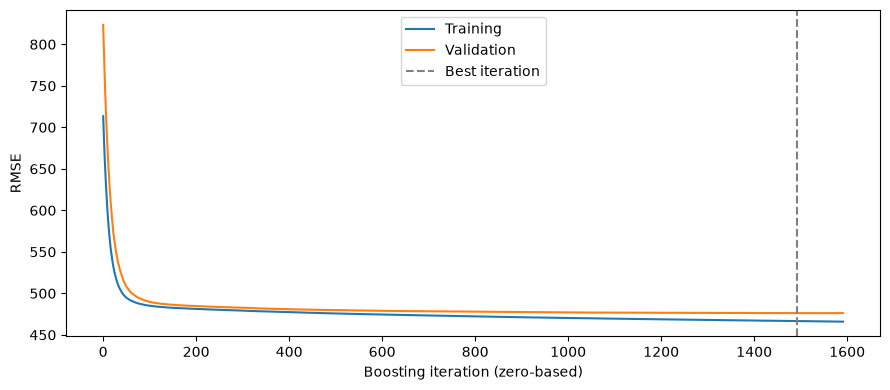

In [9]:
cb_validation_model = CatBoostRegressor(iterations=MAX_TREES, **CB_PARAMS)
cb_validation_model.fit(
    X_cb_fit, y_cb_fit,
    cat_features=CB_CATEGORICAL,
    eval_set=(X_cb_val, y_cb_val),
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
    use_best_model=True,
    verbose=200,
)
cb_val_predictions = cb_validation_model.predict(X_cb_val)
cb_best_trees = cb_validation_model.tree_count_
print(f"Selected number of trees: {cb_best_trees}")
print(f"Validation RMSE: {np.sqrt(mean_squared_error(y_cb_val, cb_val_predictions)):.2f}")
print(f"Validation MAE:  {mean_absolute_error(y_cb_val, cb_val_predictions):.2f}")

history = cb_validation_model.get_evals_result()
plt.figure(figsize=(9, 4))
plt.plot(history["learn"]["RMSE"], label="Training")
plt.plot(history["validation"]["RMSE"], label="Validation")
plt.axvline(cb_best_trees - 1, color="grey", linestyle="--", label="Best iteration")
plt.xlabel("Boosting iteration (zero-based)")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()
plt.show()


,Rows,RMSE,MAE,Mean_residual,Squared_error_share_pct
Rent_band,,,,,
Low,2107,1134.652623,1023.181989,-1020.287497,34.033515
Medium,32439,385.159909,302.882365,92.430574,60.376236
High,612,853.260466,718.298517,699.416460,5.590248


,Rows,RMSE,MAE,Mean_residual,Squared_error_share_pct
FLAT_MODEL,,,,,
adjoined flat,47,1289.740097,1055.873721,166.619483,0.980886
terrace,8,1280.300548,1043.346955,338.991930,0.164524
premium apartment loft,16,1085.107964,649.776336,-428.878696,0.236365
premium maisonette,2,1016.068640,882.018673,882.018673,0.025906
maisonette,515,604.512836,464.199071,69.195715,2.361211
apartment,1010,573.256735,414.169980,82.016705,4.164244
3gen,5,545.538975,353.033146,353.033146,0.018670
standard,1343,527.280049,399.376701,29.350741,4.684628
simplified,1567,476.400244,366.350007,53.172997,4.461998


,Rows,RMSE,MAE,Mean_residual,Squared_error_share_pct
TOWN,,,,,
bukit timah,93,657.255420,484.682295,90.409514,0.504043
jurong west,2467,582.553585,451.024487,102.474819,10.504063
kallang/whampoa,1365,536.628759,410.812509,57.732763,4.931704
bishan,760,528.118484,395.195254,79.434697,2.659456
bukit merah,2016,518.460186,382.734529,63.639701,6.798886
clementi,1269,514.895865,401.789391,119.735929,4.221015
geylang,1024,502.579820,391.849894,23.492715,3.245088
toa payoh,1387,497.047755,390.538608,59.274987,4.299215
queenstown,1490,492.195200,358.321235,44.401976,4.528741


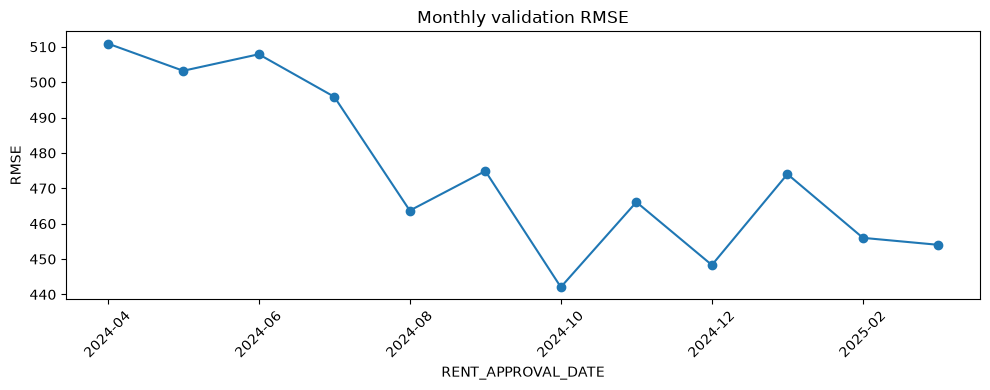

In [10]:
# Actual-rent bands are for evaluation only, never for routing predictions.
cb_errors = cb_train.loc[cb_val_mask, [
    "RENT_APPROVAL_DATE", "TOWN", "FLAT_TYPE", "FLAT_MODEL", CB_TARGET
]].copy()
cb_errors["Predicted"] = cb_val_predictions
cb_errors["Residual"] = y_cb_val - cb_val_predictions  # Positive = underprediction.
cb_errors["Squared_error"] = cb_errors["Residual"] ** 2
cb_errors["Absolute_error"] = cb_errors["Residual"].abs()
cb_errors["Rent_band"] = pd.cut(
    y_cb_val, [-np.inf, 2000, 4500, np.inf], labels=["Low", "Medium", "High"]
)


def cb_error_summary(group):
    summary = cb_errors.groupby(group, observed=True).agg(
        Rows=("Residual", "size"),
        RMSE=("Squared_error", lambda x: np.sqrt(x.mean())),
        MAE=("Absolute_error", "mean"),
        Mean_residual=("Residual", "mean"),
        SSE=("Squared_error", "sum"),
    )
    total = cb_errors["Squared_error"].sum()
    summary["Squared_error_share_pct"] = 100 * summary["SSE"] / total if total else 0.0
    return summary.drop(columns="SSE")


display(cb_error_summary("Rent_band"))
display(cb_error_summary("FLAT_MODEL").sort_values("RMSE", ascending=False))
display(cb_error_summary("TOWN").sort_values("RMSE", ascending=False))
cb_monthly_metrics = cb_error_summary("RENT_APPROVAL_DATE")
cb_monthly_metrics["RMSE"].plot(figsize=(10, 4), marker="o", title="Monthly validation RMSE")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Optional final refit and submission

Run the next cell after reviewing validation results. It refits on all labels with the selected number of trees, preserves test row order. The zero-based Id convention matches the existing project submissions; verify against the competition sample submission. No leaderboard upload is performed.

This writes predictions/catboost_location_submission.csv when run.


In [11]:
cb_final_model = CatBoostRegressor(iterations=cb_best_trees, **CB_PARAMS)
cb_final_model.fit(cb_features, cb_y, cat_features=CB_CATEGORICAL, verbose=200)
cb_test_predictions = cb_final_model.predict(cb_test_features)
assert np.isfinite(cb_test_predictions).all()

cb_submission = pd.DataFrame({
    "Id": np.arange(len(cb_test)),
    "Predicted": cb_test_predictions,
})
cb_output = CB_ROOT / "predictions/catboost_location_submission.csv"
cb_output.parent.mkdir(parents=True, exist_ok=True)
cb_submission.to_csv(cb_output, index=False)
print(f"Saved {len(cb_submission):,} rows to {cb_output}")
display(cb_submission.head())


0:	learn: 730.6856083	total: 27.9ms	remaining: 41.5s
200:	learn: 480.4809304	total: 4.02s	remaining: 25.8s
400:	learn: 476.8694557	total: 8.09s	remaining: 22s
600:	learn: 474.1820417	total: 12.4s	remaining: 18.3s
800:	learn: 472.3036113	total: 16.7s	remaining: 14.4s
1000:	learn: 470.6725373	total: 21.2s	remaining: 10.4s
1200:	learn: 469.2772834	total: 25.8s	remaining: 6.26s
1400:	learn: 467.9163669	total: 30.6s	remaining: 1.99s
1491:	learn: 467.3115078	total: 32.7s	remaining: 0us
Saved 50,000 rows to /Users/apple/Documents/modules/CS5228/cs-5228-2610-project/predictions/catboost_location_submission.csv


,Id,Predicted
0,0,2696.074652
1,1,3775.986062
2,2,3112.909309
3,3,3135.264509
4,4,3307.556058


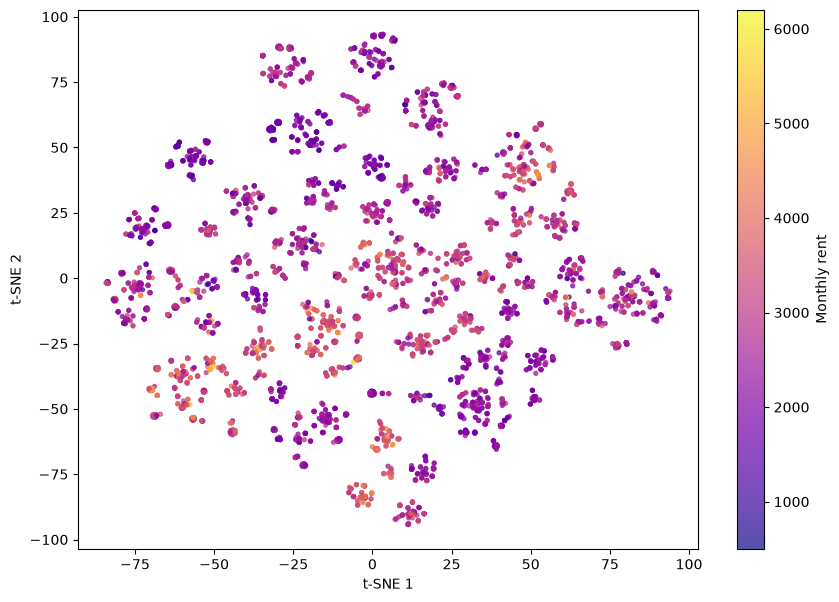

In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

sample = cb_features.sample(n=min(5000, len(cb_features)), random_state=42)
cols = ['FLAT_TYPE', 'FLAT_MODEL','HDB_PLANNING_AREA', 'FLOOR_AREA_SQM', 'APPROVAL_YEAR']

X = OneHotEncoder(handle_unknown="ignore").fit_transform(
    sample[cols].fillna("<MISSING>").astype(str)
)
X_reduced = TruncatedSVD(
    n_components=min(30, X.shape[1] - 1), random_state=42
).fit_transform(X)

embedding = TSNE(
    n_components=2, perplexity=30,
    init="pca", learning_rate="auto", random_state=42
).fit_transform(X_reduced)

plt.figure(figsize=(10, 7))
points = plt.scatter(
    embedding[:, 0], embedding[:, 1],
    c=cb_y.loc[sample.index], cmap="plasma", s=8, alpha=0.7
)
plt.colorbar(points, label="Monthly rent")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

## 5. Clustering and low-rent specialist experiments

Run section 3's imports and feature-preparation cells first. Section 3's model fit and section 4's submission are not required. These experiments preserve all observations and compare five approaches on the same chronological validation rows.

All new regressors and the classifier use a fixed 600-tree budget, configurable below. This avoids using outer validation labels for model fitting or early stopping. Repeat on other historical cutoffs before choosing a winner. No submission files are produced.

Compare overall RMSE first; improvements in low-rent errors alone may worsen the competition score.


In [ ]:
from catboost import CatBoostClassifier
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score,
)

EXP_TREES = 600
N_GEO_CLUSTERS = 8
MIN_CLUSTER_ROWS = 1000
MIN_BAND_ROWS = 100
LOW_RENT_CUTOFF = 2000
LOW_PROB_THRESHOLD = 0.5  # For diagnostics only; mixture uses probabilities.
exp_predictions, exp_models = {}, {}
exp_fit, exp_val = X_cb_fit.copy(), X_cb_val.copy()
exp_y_fit, exp_y_val = y_cb_fit.copy(), y_cb_val.copy()
assert exp_fit.index.equals(exp_y_fit.index)
assert exp_val.index.equals(exp_y_val.index)

def fit_exp_regressor(X, y, cats):
    model = CatBoostRegressor(iterations=EXP_TREES, **CB_PARAMS)
    model.fit(X, y, cat_features=cats, verbose=False)
    return model

exp_models["Global: current features"] = fit_exp_regressor(
    exp_fit, exp_y_fit, CB_CATEGORICAL
)
exp_predictions["Global: current features"] = exp_models[
    "Global: current features"
].predict(exp_val)
print("Baseline finished.")


### A. Richer global model and geographic cluster feature

Add STREET and LOCATION_KEY without altering section 3's feature lists. Then compare the same model with geographic cluster labels. K-means uses approximate local kilometres, with equal units for both axes. Fit the coordinate imputer and cluster centres only on the fitting period. Clusters partition geography, not rental regimes; they may add nothing beyond the existing coordinates.


In [ ]:
exp_rich_fit, exp_rich_val = exp_fit.copy(), exp_val.copy()
EXP_CATEGORICAL = list(CB_CATEGORICAL)
for col in ["STREET", "LOCATION_KEY"]:
    for X in [exp_rich_fit, exp_rich_val]:
        X[col] = (
            cb_train.loc[X.index, col].astype("string").str.strip().str.lower()
            .str.replace(r"\s+", " ", regex=True)
            .fillna("<missing>").replace("", "<missing>").astype(object)
        )
    if col not in EXP_CATEGORICAL:
        EXP_CATEGORICAL.append(col)

exp_models["Global: addresses"] = fit_exp_regressor(
    exp_rich_fit, exp_y_fit, EXP_CATEGORICAL
)
exp_predictions["Global: addresses"] = exp_models["Global: addresses"].predict(exp_rich_val)

GEO_COLS = ["HDB_LATITUDE", "HDB_LONGITUDE"]
assert exp_rich_fit[GEO_COLS].notna().any().all()
geo_imputer = SimpleImputer(strategy="median")
geo_fit_degrees = geo_imputer.fit_transform(exp_rich_fit[GEO_COLS])
geo_val_degrees = geo_imputer.transform(exp_rich_val[GEO_COLS])
geo_origin = geo_fit_degrees.mean(axis=0)
geo_scale = np.array([111.195, 111.195 * np.cos(np.radians(geo_origin[0]))])
geo_fit_km = (geo_fit_degrees - geo_origin) * geo_scale
geo_val_km = (geo_val_degrees - geo_origin) * geo_scale
assert len(np.unique(geo_fit_km, axis=0)) >= N_GEO_CLUSTERS

geo_clusterer = KMeans(n_clusters=N_GEO_CLUSTERS, n_init=10, random_state=42)
fit_clusters = geo_clusterer.fit_predict(geo_fit_km)
val_clusters = geo_clusterer.predict(geo_val_km)

exp_geo_fit, exp_geo_val = exp_rich_fit.copy(), exp_rich_val.copy()
exp_geo_fit["GEO_CLUSTER"] = fit_clusters.astype(str)
exp_geo_val["GEO_CLUSTER"] = val_clusters.astype(str)
exp_models["Global: addresses + cluster"] = fit_exp_regressor(
    exp_geo_fit, exp_y_fit, EXP_CATEGORICAL + ["GEO_CLUSTER"]
)
exp_predictions["Global: addresses + cluster"] = exp_models[
    "Global: addresses + cluster"
].predict(exp_geo_val)
display(pd.DataFrame({
    "Fit_rows": pd.Series(fit_clusters).value_counts(),
    "Validation_rows": pd.Series(val_clusters).value_counts(),
}).fillna(0).astype(int).sort_index())
print("Address and cluster-feature experiments finished.")


### B. Separate geographic regressors

Fit one expert per sufficiently large training cluster, with the same richer features. Use the global address model for small clusters. Validation routes depend only on coordinates, never actual rent. Local specialization may lose information available from pooling locations.


In [ ]:
geo_experts, geo_expert_summary = {}, []
geo_specialist_predictions = exp_predictions["Global: addresses"].copy()
for cluster_id in range(N_GEO_CLUSTERS):
    fit_member = fit_clusters == cluster_id
    val_member = val_clusters == cluster_id
    use_expert = fit_member.sum() >= MIN_CLUSTER_ROWS
    if use_expert:
        geo_experts[cluster_id] = fit_exp_regressor(
            exp_rich_fit.loc[fit_member], exp_y_fit.loc[fit_member], EXP_CATEGORICAL
        )
        if val_member.any():
            geo_specialist_predictions[val_member] = geo_experts[cluster_id].predict(
                exp_rich_val.loc[val_member]
            )
    geo_expert_summary.append({
        "Cluster": cluster_id, "Fit_rows": int(fit_member.sum()),
        "Validation_rows": int(val_member.sum()),
        "Model": "Local expert" if use_expert else "Global fallback",
    })
exp_predictions["Geographic experts"] = geo_specialist_predictions
display(pd.DataFrame(geo_expert_summary))


### C. Low-rent classifier and probability-weighted experts

Predict P(rent <=2,000 | features), then combine two regressors trained on low/other fitting rows. Every validation row receives both predictions. Validation rent is used only for reporting.

No class balancing: the mixture requires probabilities on the original prevalence scale. Temporal drift may still impair calibration. Compare average precision against validation low-rent prevalence, and inspect Brier score and probability bins. Accuracy alone is misleading for this rare class.


In [ ]:
low_fit = (exp_y_fit <= LOW_RENT_CUTOFF).astype(int)
low_val = (exp_y_val <= LOW_RENT_CUTOFF).astype(int)
assert low_fit.value_counts().reindex([0, 1], fill_value=0).min() >= MIN_BAND_ROWS
classifier_params = {
    k: v for k, v in CB_PARAMS.items() if k not in ["loss_function", "eval_metric"]
}
low_rent_classifier = CatBoostClassifier(
    iterations=EXP_TREES, loss_function="Logloss", eval_metric="Logloss",
    **classifier_params,
)
low_rent_classifier.fit(
    exp_rich_fit, low_fit, cat_features=EXP_CATEGORICAL, verbose=False
)
low_probability = low_rent_classifier.predict_proba(exp_rich_val)[:, 1]
low_decision = low_probability >= LOW_PROB_THRESHOLD
both_classes = low_val.nunique() == 2
display(pd.Series({
    "Training_low_prevalence": low_fit.mean(),
    "Validation_low_prevalence": low_val.mean(),
    "Average_precision": average_precision_score(low_val, low_probability)
        if both_classes else np.nan,
    "ROC_AUC": roc_auc_score(low_val, low_probability) if both_classes else np.nan,
    "Brier_score": brier_score_loss(low_val, low_probability),
    "Brier_constant_training_prevalence": brier_score_loss(
        low_val, np.full(len(low_val), low_fit.mean())
    ),
    "Precision_at_threshold": precision_score(low_val, low_decision, zero_division=0),
    "Recall_at_threshold": recall_score(low_val, low_decision, zero_division=0),
    "Predicted_low_rows": low_decision.sum(),
}, name="Low-rent classifier diagnostics"))

probability_bins = pd.DataFrame({
    "Probability": low_probability, "Actual_low": low_val.to_numpy()
})
probability_bins["Bin"] = pd.cut(
    probability_bins["Probability"], np.linspace(0, 1, 11), include_lowest=True
)
display(probability_bins.groupby("Bin", observed=True).agg(
    Rows=("Actual_low", "size"), Mean_probability=("Probability", "mean"),
    Observed_low_rate=("Actual_low", "mean"),
))

band_experts = {}
for label, mask in [("Low", low_fit.eq(1)), ("Other", low_fit.eq(0))]:
    band_experts[label] = fit_exp_regressor(
        exp_rich_fit.loc[mask], exp_y_fit.loc[mask], EXP_CATEGORICAL
    )
low_expert_prediction = band_experts["Low"].predict(exp_rich_val)
other_expert_prediction = band_experts["Other"].predict(exp_rich_val)
exp_predictions["Low/other soft mixture"] = (
    low_probability * low_expert_prediction
    + (1 - low_probability) * other_expert_prediction
)


### D. Overall, rent-band and monthly comparison

Positive residual = underprediction. Report rent bands at the fixed 2,000/4,500 boundaries even if the classifier threshold changes. Compare against the identically budgeted global models here, not section 3's early-stopped model. No final training or exports occur.


In [ ]:
exp_score_rows, exp_band_rows = [], []
exp_monthly = pd.DataFrame(index=exp_y_val.index)
exp_monthly["Month"] = cb_dates.loc[exp_y_val.index].dt.strftime("%Y-%m")
actual = exp_y_val.to_numpy()
band_masks = {
    "Low": actual <= 2000,
    "Medium": (actual > 2000) & (actual <= 4500),
    "High": actual > 4500,
}
for name, prediction in exp_predictions.items():
    assert prediction.shape == actual.shape and np.isfinite(prediction).all()
    residual = actual - prediction
    squared = residual ** 2
    exp_score_rows.append({
        "Model": name, "RMSE": np.sqrt(squared.mean()),
        "MAE": np.abs(residual).mean(), "Mean_residual": residual.mean(),
    })
    exp_monthly[name] = squared
    for band, mask in band_masks.items():
        if mask.any():
            exp_band_rows.append({
                "Model": name, "Band": band, "Rows": int(mask.sum()),
                "RMSE": np.sqrt(squared[mask].mean()),
                "MAE": np.abs(residual[mask]).mean(),
                "Mean_residual": residual[mask].mean(),
                "Squared_error_share_pct": 100 * squared[mask].sum() / squared.sum()
                    if squared.sum() else 0.0,
            })
exp_scores = pd.DataFrame(exp_score_rows).set_index("Model").sort_values("RMSE")
exp_scores["RMSE_change_vs_addresses"] = (
    exp_scores["RMSE"] - exp_scores.loc["Global: addresses", "RMSE"]
)
exp_band_scores = pd.DataFrame(exp_band_rows)
display(exp_scores)
display(exp_band_scores.pivot(index="Model", columns="Band", values="RMSE"))
display(exp_band_scores)
exp_monthly_rmse = np.sqrt(exp_monthly.groupby("Month").mean())
exp_monthly_rmse.plot(figsize=(12, 5), marker="o")
plt.ylabel("Validation RMSE")
plt.title("Monthly errors: global models vs specialists")
plt.xticks(rotation=45)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
